# Deep Neural Network Architecture

1. Single Neuron
2. Single-layer Network
3. Hidden Layers
5. Fully connected Dense layers
6. Neurons/layer
7. Depth vs Width
8. Regularization

$ Z = W.X + b $

then

$ a = F(z) $

$$ MNIST CLASSIFICATION $$

In [1]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt



(60000, 28, 28) (10000, 28, 28) (60000,) (10000,)


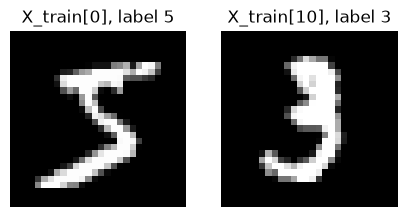

[[  0   0  42 118 219 166 118 118   6   0   0]
 [  0 103 242 254 254 254 254 254  66   0   0]
 [  0  18 232 254 254 254 254 254 238  70   0]
 [  0   0 104 244 254 224 254 254 254 141   0]
 [  0   0   0 207 254 210 254 254 254  34   0]]


In [3]:
# load the data

(X_train,y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print(X_train.shape,X_test.shape, y_train.shape, y_test.shape)

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
for ax, i in zip(axes, [0, 10]):    
    ax.imshow(X_train[i], cmap="gray"); ax.set_title(f"X_train[{i}], label {y_train[i]}"); ax.axis("off")
plt.show()
print(X_train[10][4:9, 9:20])

In [4]:
# inspect
X_train[10]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  42, 118,
        219, 166, 118, 118,   6,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 103, 242, 254,
        254, 254, 254, 254,  66,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [5]:
print(X_train[10])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  42 118 219 166 118 118   6
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 103 242 254 254 254 254 254  66
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  18 232 254 254 254 254 254 238
   70   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0 104 244 254 224 254 254 254
  141   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0 207 254 210 25

In [6]:
# Data Preprocessing - Flatten

X_train = X_train.reshape(-1,28*28)
X_test = X_test.reshape(-1,28*28)

# Normalization

X_train.shape

(60000, 784)

In [7]:
X_train[10]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,  42, 118, 219, 166, 118, 118,   6,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0, 103, 242, 254, 254, 254, 254,
       254,  66,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,  18, 232, 25

In [8]:
# normalize
X_train = X_train/255.0
X_test = X_test/255.0

X_train[10]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

## 1. One Neuron Architecture

In [9]:
model_single = keras.models.Sequential()
model_single.add(keras.layers.Dense(1, input_shape=(28*28,)))
model_single.add(keras.layers.Dense(10, activation='softmax'))
model_single.summary()

c:\Users\UTL2397\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │           785 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            20 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 805 (3.14 KB)

 Trainable params: 805 (3.14 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# see the weigth matrix
for layer in model_single.layers:
    print(layer.name)
    weights,bias = layer.get_weights()
    print(bias.shape)
    print(weights.shape)
    print(weights[:3])

dense
(1,)
(784, 1)
[[0.0272717 ]
 [0.0699288 ]
 [0.04009037]]
dense_1
(10,)
(1, 10)
[[ 0.06439102 -0.52101576  0.17228687  0.2819869   0.44540828 -0.10218865
   0.28933924  0.6306557   0.6753183   0.51047057]]


In [11]:
# compilation
model_single.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
# train the model with data
model_single.fit(X_train,y_train,epochs=10, batch_size = 128)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2729 - loss: 1.7759
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3183 - loss: 1.6468
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3381 - loss: 1.6210
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 887us/step - accuracy: 0.3630 - loss: 1.6070
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 884us/step - accuracy: 0.3790 - loss: 1.5957
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 981us/step - accuracy: 0.3863 - loss: 1.5872
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step - accuracy: 0.3904 - loss: 1.5816
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.3995 - loss: 1.5766
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 889us/step - accuracy: 0.4002 - loss: 1.5756
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 901us/step - accuracy: 0.4021 - loss: 1.5720


`Observation -
**1 layer for Hudden and 10 neuron @ O/p - > Low convergence, showing poor Loss metrics**`

## Shallow Network

In [13]:
model_shallow = keras.models.Sequential()
model_shallow.add(keras.layers.Dense(100, input_shape=(28*28,),activation='relu'))
model_shallow.add(keras.layers.Dense(10, activation='softmax'))
model_shallow.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# model compile
model_shallow.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [15]:
# train
model_shallow.fit(X_train,y_train,epochs=10, batch_size = 128, validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8611 - loss: 0.5183 - val_accuracy: 0.9172 - val_loss: 0.2927
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9195 - loss: 0.2819 - val_accuracy: 0.9325 - val_loss: 0.2422
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9329 - loss: 0.2338 - val_accuracy: 0.9422 - val_loss: 0.2083
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9430 - loss: 0.2018 - val_accuracy: 0.9469 - val_loss: 0.1882
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9492 - loss: 0.1787 - val_accuracy: 0.9509 - val_loss: 0.1724
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9536 - loss: 0.1601 - val_accuracy: 0.9557 - val_loss: 0.1609
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9583 - loss: 0.1455 - val_accuracy: 0.9579 - val_loss: 0.1497
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9615 - loss: 0.1331 - val_accuracy: 0.

In [16]:
# testing
model_shallow.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 964us/step - accuracy: 0.9628 - loss: 0.1246


[0.12463545799255371, 0.9628000259399414]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9628 - loss: 0.1246


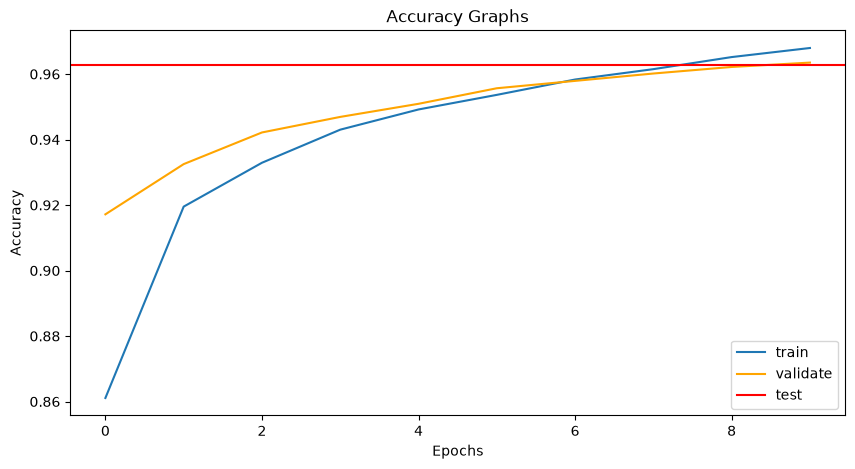

In [17]:
# draw graph for accuracy of train,test,validate
plt.figure(figsize=(10,5))
plt.plot(model_shallow.history.history['accuracy'],label = 'train')
plt.plot(model_shallow.history.history['val_accuracy'], color='orange', label = 'validate')
plt.title('Accuracy Graphs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train','test'])
plt.axhline(model_shallow.evaluate(X_test,y_test)[1], label = 'test', color='red')
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 932us/step - accuracy: 0.9628 - loss: 0.1246


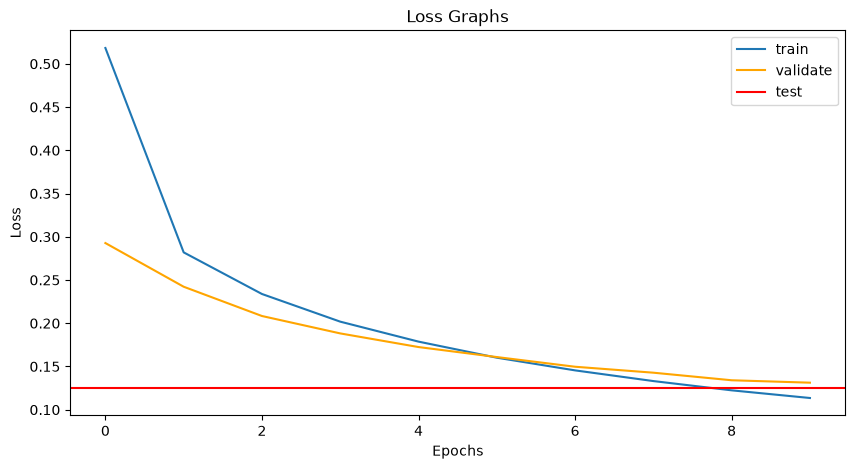

In [18]:
# loss graph
plt.figure(figsize=(10,5))
plt.plot(model_shallow.history.history['loss'],label = 'train')
plt.plot(model_shallow.history.history['val_loss'], color='orange', label = 'validate')
plt.title('Loss Graphs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train','test'])
plt.axhline(model_shallow.evaluate(X_test,y_test)[0], label = 'test', color='red')
plt.legend()
plt.show()

In [19]:
# check model weights
for layer in model_shallow.layers:
    print(layer.name)
    weights,bias = layer.get_weights()
    print(bias.shape)
    print(weights.shape)
    print(weights[:1])
    print(bias[:5])

dense_2
(100,)
(784, 100)
[[-0.0474694   0.01370737 -0.06578905  0.03256936  0.01364269 -0.08128948
  -0.01475787  0.0453264   0.04233221 -0.05751259 -0.00188372 -0.0357204
  -0.06763119  0.07313295  0.06365177 -0.04640892 -0.07515955  0.04658969
   0.06274226 -0.01282936  0.0563181  -0.00987263 -0.01443421  0.06911036
   0.05651867  0.0757225   0.06827986  0.02105885  0.06381918  0.05419658
  -0.07238007  0.01717343  0.01331694  0.08038661 -0.03470511  0.00617762
   0.08054015 -0.02806842 -0.00720585 -0.04105753  0.01294688  0.00602184
   0.02707285 -0.0689472   0.06260765 -0.01377494  0.01103686  0.0499814
  -0.05032832  0.05975741 -0.04080039  0.04390121  0.0162081  -0.07056467
  -0.07769223  0.0795238   0.05892371  0.01426014  0.07132752  0.06600131
   0.05488707 -0.02314447 -0.00786186 -0.02361107  0.03125235 -0.01271591
   0.03186619 -0.03013764 -0.05861744  0.00256087  0.03480639  0.06509726
  -0.00978925 -0.00583664  0.06549297  0.06150374  0.01345097  0.01565171
  -0.01756352 

## 3. Fully Connected Layers

In [20]:
model_dnn = keras.models.Sequential()

#hidden layers
model_dnn.add(keras.layers.Dense(20, input_shape=(28*28,),activation='relu'))
model_dnn.add(keras.layers.Dense(20, activation='relu'))
model_dnn.add(keras.layers.Dense(20, activation='relu'))
model_dnn.add(keras.layers.Dense(20, activation='relu'))
model_dnn.add(keras.layers.Dense(20, activation='relu'))

#output layer
model_dnn.add(keras.layers.Dense(10, activation='softmax'))
model_dnn.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,590 (68.71 KB)

 Trainable params: 17,590 (68.71 KB)

 Non-trainable params: 0 (0.00 B)

**Observation - By increasing depth the parameter size actually decreases, given number of neurons remain same**

In [21]:
# compile the dnn
model_dnn.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [22]:
# fit
model_dnn.fit(X_train,y_train,epochs=10, batch_size = 128, validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6499 - loss: 1.0802 - val_accuracy: 0.8763 - val_loss: 0.4331
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8955 - loss: 0.3586 - val_accuracy: 0.9203 - val_loss: 0.2657
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9221 - loss: 0.2655 - val_accuracy: 0.9318 - val_loss: 0.2255
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9341 - loss: 0.2223 - val_accuracy: 0.9394 - val_loss: 0.2014
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9425 - loss: 0.1911 - val_accuracy: 0.9469 - val_loss: 0.1766
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9470 - loss: 0.1749 - val_accuracy: 0.9442 - val_loss: 0.1860
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9532 - loss: 0.1585 - val_accuracy: 0.9498 - val_loss: 0.1673
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9536 - loss: 0.1505 - val_accuracy: 0.

In [23]:
# test
model_dnn.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9521 - loss: 0.1640


[0.16404588520526886, 0.9520999789237976]

## Perfect Architectures for DNN

In [24]:
# achitecture of 784-> 2048->2048 - > 10
model_dnn_perfect = keras.models.Sequential()

#hidden layers
model_dnn_perfect.add(keras.layers.Dense(2048, input_shape=(28*28,),activation='relu'))
model_dnn_perfect.add(keras.layers.Dense(2048, activation='relu'))
model_dnn_perfect.add(keras.layers.Dense(10, activation='softmax'))
model_dnn_perfect.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 2048)           │     1,607,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2048)           │     4,196,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,824,522 (22.22 MB)

 Trainable params: 5,824,522 (22.22 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# compile
model_dnn_perfect.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [26]:
# train
model_dnn_perfect.fit(X_train,y_train,epochs=10, batch_size = 128, validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8861 - loss: 0.4192 - val_accuracy: 0.9283 - val_loss: 0.2438
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9420 - loss: 0.2008 - val_accuracy: 0.9540 - val_loss: 0.1645
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9580 - loss: 0.1472 - val_accuracy: 0.9613 - val_loss: 0.1367
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9672 - loss: 0.1146 - val_accuracy: 0.9667 - val_loss: 0.1175
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9737 - loss: 0.0930 - val_accuracy: 0.9701 - val_loss: 0.1041
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.9786 - loss: 0.0770 - val_accuracy: 0.9712 - val_loss: 0.1025
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9825 - loss: 0.0647 - val_accuracy: 0.9737 - val_loss: 0.0886
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9847 - loss: 0.0548 - val_ac

In [27]:
# test
model_dnn_perfect.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9783 - loss: 0.0724


[0.072362020611763, 0.9782999753952026]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9783 - loss: 0.0724


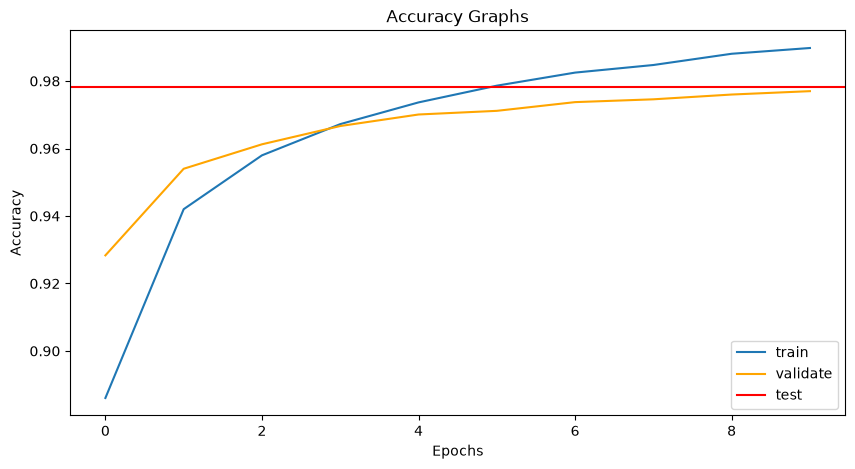

In [28]:
# plot
plt.figure(figsize=(10,5))
plt.plot(model_dnn_perfect.history.history['accuracy'],label = 'train')
plt.plot(model_dnn_perfect.history.history['val_accuracy'], color='orange', label = 'validate')
plt.title('Accuracy Graphs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train','validate','test'])
plt.axhline(model_dnn_perfect.evaluate(X_test,y_test)[1], label = 'test', color='red')
plt.legend()
plt.show()

## Overfitting - Regularization

In [29]:
model_3 = keras.models.Sequential()

#hidden layers
model_3.add(keras.layers.Dense(20, input_shape=(28*28,),activation='relu'))
model_3.add(keras.layers.Dense(20, activation='relu'))
model_3.add(keras.layers.Dense(20, activation='relu'))
model_3.add(keras.layers.Dense(20, activation='relu'))
model_3.add(keras.layers.Dense(20, activation='relu'))


#output layer
model_3.add(keras.layers.Dense(10, activation='softmax'))
model_3.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,590 (68.71 KB)

 Trainable params: 17,590 (68.71 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compile
model_3.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# epochs of 100
model_3.fit(X_train,y_train,epochs=100, batch_size = 128, validation_split=0.2)

In [ ]:
# plot train vs validate loss
plt.figure(figsize=(10,5))
plt.plot(model_3.history.history['loss'],label = 'train')
plt.plot(model_3.history.history['val_loss'], color='orange', label = 'validate')

plt.title('Loss Graphs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train','validate'])

In [ ]:
#evaluate
model_3.evaluate(X_test,y_test)

In [ ]:
# 1. Early stopping
# 2. Dropouts
# 3. L2 Regularization

